## Problem Title: The "RapidRoute" Performance Audit

--- Aggregation ---
     zone  total_delivery  avg_efficiency_score  low_rating_percentage
0  Zone_A            2419              1.083691              20.835056
1  Zone_B            2576              1.473434              19.254658
2  Zone_C            2478              1.000519              19.774011
3  Zone_D            2516              1.248009              19.475358

--- Anomalies ---
Found 30 anomalies. First 5: ['ORD_124' 'ORD_280' 'ORD_300' 'ORD_348' 'ORD_826']

--- Generating Report ---


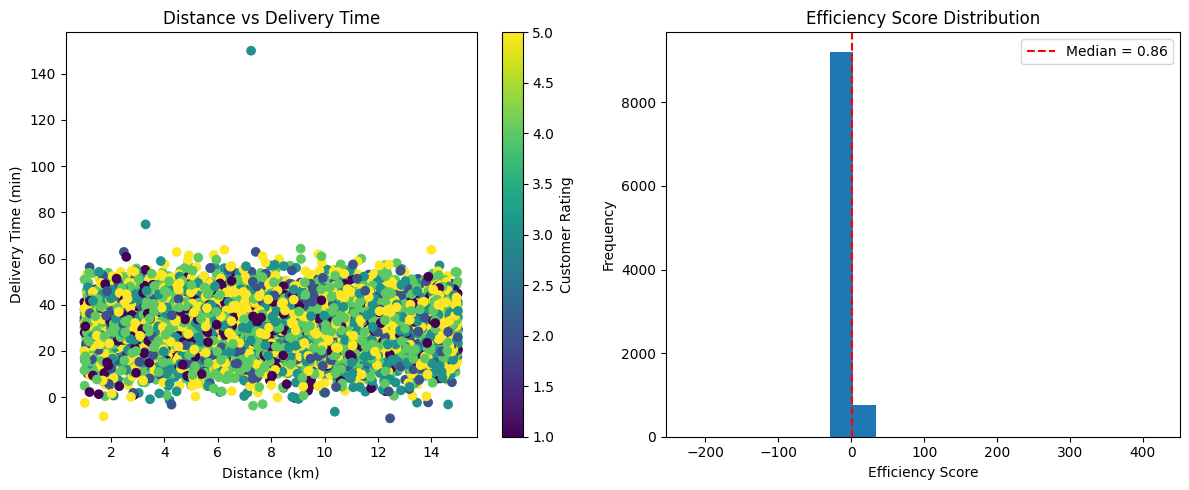

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

class DeliveryAnalyzer:
    def __init__(self):
        pass
        
    def clean_and_aggregate(self, df: pd.DataFrame) -> pd.DataFrame:
        df.dropna(subset=['delivery_time_min'], inplace=True)
        df["efficiency_score"] = (df["distance_km"] / df['delivery_time_min']) * df['customer_rating']
        df = df.groupby("zone").agg(total_delivery=('order_id', 'count'),
                                    avg_efficiency_score= ( 'efficiency_score', 'mean'),
                                    low_rating_percentage =('customer_rating', lambda x: ((x <= 2).sum() / len(x)) * 100)
                                    ).reset_index()
        
        return df

    def find_anomalies(self, df: pd.DataFrame) -> np.ndarray:
        delivery_time_min = df['delivery_time_min'].to_numpy()
        mean = np.mean(delivery_time_min)
        std = np.std(delivery_time_min)
        Z = (delivery_time_min - mean) / std
        outlier_order = df['order_id'][np.abs(Z) > 3.0].to_numpy()
        return outlier_order

    def generate_diagrammatic_report(self, df: pd.DataFrame):
        fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12, 5))

        scatter = ax1.scatter(df['distance_km'], df['delivery_time_min'], c=df["customer_rating"], cmap='viridis')
        ax1.set_title('Distance vs Delivery Time')
        ax1.set_xlabel('Distance (km)')
        ax1.set_ylabel('Delivery Time (min)')
        cbar = fig.colorbar(scatter, ax=ax1)
        cbar.set_label('Customer Rating')
        df["efficiency_score"] = (df["distance_km"] / df['delivery_time_min']) * df['customer_rating']
        # print(df.columns)

        ax2.hist(df['efficiency_score'], bins= 20)
        median_efficiency = np.median(df['efficiency_score'])
        ax2.axvline(median_efficiency, color='red', linestyle='--', label=f'Median = {median_efficiency:.2f}')
        ax2.set_title('Efficiency Score Distribution')
        ax2.set_xlabel('Efficiency Score')
        ax2.set_ylabel('Frequency')
        ax2.legend()

        plt.tight_layout()
        plt.show()


# --- Local Testing ---
# Generate mock data to test your solution
if __name__ == "__main__":
    np.random.seed(42)
    n = 10000
    mock_df = pd.DataFrame({
        'order_id': [f"ORD_{i}" for i in range(n)],
        'distance_km': np.random.uniform(1.0, 15.0, n),
        'delivery_time_min': np.random.normal(30, 10, n),
        'customer_rating': np.random.choice([1, 2, 3, 4, 5], n, p=[0.1, 0.1, 0.2, 0.3, 0.3]),
        'zone': np.random.choice(['Zone_A', 'Zone_B', 'Zone_C', 'Zone_D'], n)
    })
    # Inject some NaNs and outliers
    mock_df.loc[10:20, 'delivery_time_min'] = np.nan
    mock_df.loc[999, 'delivery_time_min'] = 150.0 
    
    analyzer = DeliveryAnalyzer()
    
    print("--- Aggregation ---")
    agg_df = analyzer.clean_and_aggregate(mock_df.copy())
    print(agg_df)
    
    print("\n--- Anomalies ---")
    anomalies = analyzer.find_anomalies(mock_df.dropna(subset=['delivery_time_min']).copy())
    print(f"Found {len(anomalies)} anomalies. First 5: {anomalies[:5]}")
    
    print("\n--- Generating Report ---")
    # Uncomment to test your plotting function
    analyzer.generate_diagrammatic_report(mock_df.dropna().copy())

## The "Vision Pipeline" Audit

--- Log Processing ---
Top 5 Compressed High-Res Images: ['IMG_3577', 'IMG_4114', 'IMG_2909', 'IMG_3263', 'IMG_4874']

--- Image Masking ---
Center 50x50 Mean Intensity: 205.47
Masked Image Unique Values: [  0 255]

--- Visualization ---


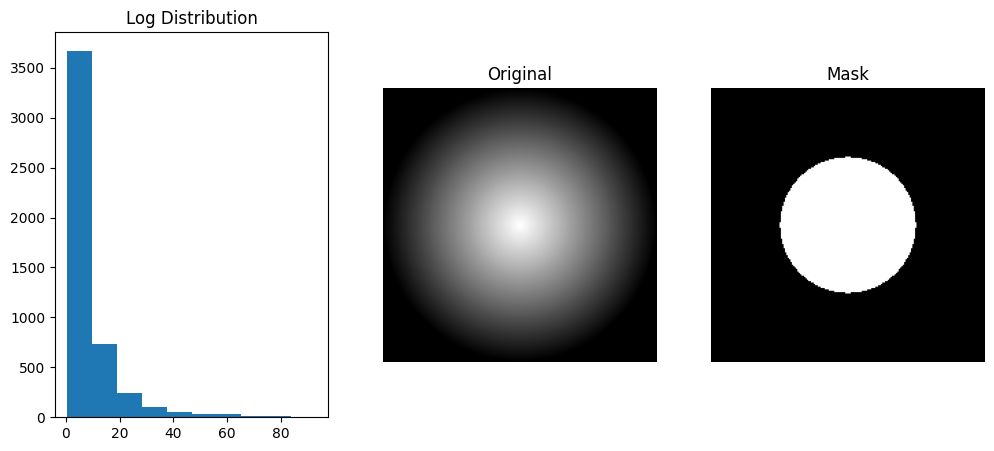

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

class VisionAuditor:
    def __init__(self):
        pass
        
    def process_upload_logs(self, df: pd.DataFrame) -> list:
        df.dropna(subset='compressed_size_kb', inplace=True)
        df['compression_ratio'] = df['original_size_kb'] / df['compressed_size_kb']
        high_res_img = df[df['width_px'] * df['height_px'] > 1000000]
        # print(high_res_img)

        return high_res_img.sort_values(by=['compression_ratio'], ascending=False).head(5)['image_id'].to_list()

    def apply_mask(self, image_matrix: np.ndarray) -> tuple:
        thresholded_matrix = np.where(image_matrix < 128, 0, 255)
        # Extract the exact 50x50 center crop
        row, col = image_matrix.shape
        startR = row // 2 -25
        startC = col // 2 -25
        center_crop = image_matrix[startR:startR + 50, startC:startC + 50]
        mean_intensity = center_crop.mean()

        return thresholded_matrix, mean_intensity
        

    def visualize_pipeline(self, log_df: pd.DataFrame, image_matrix: np.ndarray):
        log_df.dropna(subset='compressed_size_kb', inplace=True)
        log_df['compression_ratio'] = log_df['original_size_kb'] / log_df['compressed_size_kb']

        fig, ax = plt.subplots(1,3, figsize=(12,5))
        ax[0].hist(log_df['compression_ratio'])
        ax[0].set_title("Log Distribution")

        ax[1].imshow(image_matrix, cmap='gray')
        ax[1].axis('off')
        ax[1].set_title("Original")

        thresholded_matrix, mean_intensity = self.apply_mask(image_matrix)
        ax[2].imshow(thresholded_matrix, cmap='gray')
        ax[2].axis('off')
        ax[2].set_title("Mask")

# --- Local Testing ---
if __name__ == "__main__":
    np.random.seed(101)
    
    # 1. Mock DataFrame
    n = 5000
    log_data = pd.DataFrame({
        'image_id': [f"IMG_{i:04d}" for i in range(n)],
        'original_size_kb': np.random.uniform(500, 5000, n),
        'compressed_size_kb': np.random.uniform(50, 1000, n),
        'width_px': np.random.randint(500, 4000, n),
        'height_px': np.random.randint(500, 4000, n)
    })
    # Inject some NaNs
    log_data.loc[np.random.choice(n, 100, replace=False), 'compressed_size_kb'] = np.nan
    
    # 2. Mock Image Matrix (Grayscale, 200x200)
    # Creating a mock image with a bright center
    x, y = np.meshgrid(np.linspace(-1, 1, 200), np.linspace(-1, 1, 200))
    distance = np.sqrt(x*x + y*y)
    mock_image = np.clip(255 * (1 - distance), 0, 255).astype(np.uint8)
    
    auditor = VisionAuditor()
    
    print("--- Log Processing ---")
    top_images = auditor.process_upload_logs(log_data.copy())
    print(f"Top 5 Compressed High-Res Images: {top_images}")
    
    print("\n--- Image Masking ---")
    masked_img, center_mean = auditor.apply_mask(mock_image)
    print(f"Center 50x50 Mean Intensity: {center_mean:.2f}")
    print(f"Masked Image Unique Values: {np.unique(masked_img)}")
    
    print("\n--- Visualization ---")
    # Uncomment to test your plotting function
    auditor.visualize_pipeline(log_data.copy(), mock_image)

## The "Attendance System" Embeddings Audit

--- Department Turnout ---
Top Department by Unique Scans: IT

--- Finding Matches ---
Top 3 Closest Match Indices: [64, 55, 19]

--- Visualization ---


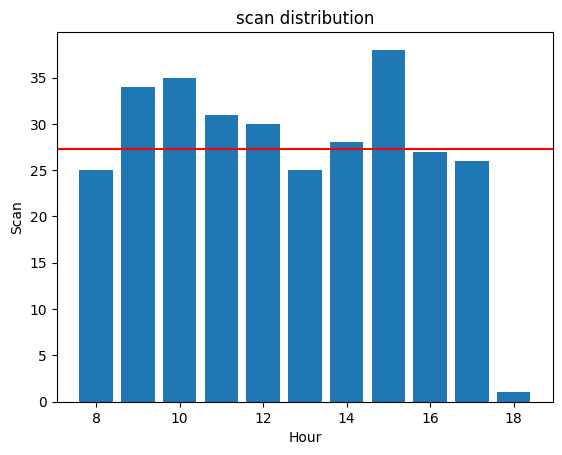

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

class AttendanceAnalytics:
    def __init__(self):
        pass
        
    def department_turnout(self, logs_df: pd.DataFrame, metadata_df: pd.DataFrame) -> str:
        filter_log = logs_df[logs_df['confidence_score'] >= 0.85]
        merge_df = pd.merge(filter_log, metadata_df, how='inner', on='student_id')
        dep_high_ss = merge_df.groupby(by='department')['student_id'].nunique().idxmax()
        return dep_high_ss

    def find_closest_matches(self, embeddings_matrix: np.ndarray, target_vector: np.ndarray) -> list:
        # print(embeddings_matrix)
        dist = np.sqrt(np.sum(np.square(embeddings_matrix - target_vector), axis=1))
        # print(dist)
        return np.argsort(dist)[:3].tolist()

    def visualize_scan_distribution(self, time_series_df: pd.DataFrame):
        time_series_df['hour'] = time_series_df['timestamp'].dt.hour
        count_hour = time_series_df.groupby('hour')['scan_id'].count()
        # print(count_hour)
        avg_scan = count_hour.mean()
        plt.bar(count_hour.index, count_hour.values)
        plt.axhline(avg_scan, color = 'red',)
        plt.title("scan distribution")
        plt.xlabel("Hour")
        plt.ylabel("Scan")
        plt.show()

# --- Local Testing ---
if __name__ == "__main__":
    np.random.seed(42)
    
    # 1. Mock DataFrames
    n_scans = 500
    logs_data = pd.DataFrame({
        'scan_id': range(n_scans),
        'student_id': np.random.randint(100, 200, n_scans),
        'confidence_score': np.random.uniform(0.6, 0.99, n_scans)
    })
    
    meta_data = pd.DataFrame({
        'student_id': range(100, 200),
        'department': np.random.choice(['Computer Science', 'Data Science', 'IT', 'Business'], 100)
    })
    
    # 2. Mock Embeddings (100 students, 128 dimensions)
    stored_embeddings = np.random.rand(100, 128)
    new_scan = np.random.rand(128)
    
    # 3. Mock Time Series
    dates = pd.date_range(start="2026-06-09 08:00:00", end="2026-06-09 18:00:00", freq='2min')
    time_df = pd.DataFrame({
        'timestamp': np.random.choice(dates, 300),
        'scan_id': range(300)
    })
    
    analytics = AttendanceAnalytics()
    
    print("--- Department Turnout ---")
    top_dept = analytics.department_turnout(logs_data.copy(), meta_data.copy())
    print(f"Top Department by Unique Scans: {top_dept}")
    
    print("\n--- Finding Matches ---")
    top_3_indices = analytics.find_closest_matches(stored_embeddings, new_scan)
    print(f"Top 3 Closest Match Indices: {top_3_indices}")
    
    print("\n--- Visualization ---")
    # Uncomment to test your plotting function
    analytics.visualize_scan_distribution(time_df.copy())

## The "OS Resource Manager" Audit

--- Starvation Audit ---
Starved processes by priority:
 priority
2      52
3     110
4     144
5     145
6     189
7     179
8     205
9     204
10    198
Name: process_id, dtype: int64

--- External Fragmentation Audit ---
Largest contiguous free block size: 16

--- Visualization ---


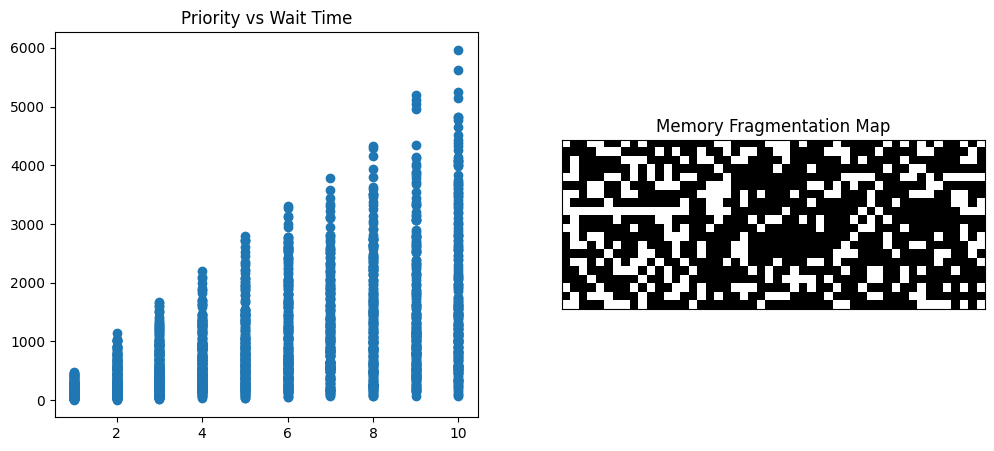

In [122]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

class OSAuditor:
    def __init__(self):
        pass
        
    def audit_starvation(self, process_df: pd.DataFrame) -> pd.Series:
        process_df['turnaround_time'] = process_df['completion_time_ms'] - process_df['arrival_time_ms']
        process_df['waiting_time'] = process_df['turnaround_time'] - process_df['burst_time_ms']
        # print(process_df)
        starved_process = process_df[process_df['waiting_time'] > 5 * process_df['burst_time_ms']]
        starrved_count = starved_process.groupby(by='priority')['process_id'].count()
        # print(starrved_count) 
        return starrved_count

    def calculate_max_free_block(self, memory_array: np.ndarray) -> int:
        # print(memory_array)
        Z_mask = (memory_array == 0).astype(int) # 1 = free
        # print(Z_mask)
        dist = np.diff(np.r_[0, Z_mask, 0])
        # print(dist)
        start = np.where(dist == 1)[0]
        # print(start)
        end = np.where(dist == -1)[0]
        max_con_block = np.max(end - start)
        return max_con_block

    def visualize_system_state(self, process_df: pd.DataFrame, memory_array: np.ndarray):
        process_df['turnaround_time'] = process_df['completion_time_ms'] - process_df['arrival_time_ms']
        process_df['waiting_time'] = process_df['turnaround_time'] - process_df['burst_time_ms']
        fig, ax = plt.subplots(1,2, figsize = (12,5))
        ax[0].scatter(process_df['priority'], process_df['waiting_time'])
        ax[0].set_title("Priority vs Wait Time")
        img = memory_array.reshape(20,50)
        ax[1].imshow(img, cmap='binary')
        # ax[1].axis('off')
        ax[1].set_xticks([])
        ax[1].set_yticks([])
        ax[1].set_title("Memory Fragmentation Map")

# --- Local Testing ---
if __name__ == "__main__":
    np.random.seed(101)
    
    # 1. Mock Process Data
    n_processes = 2000
    arrival = np.random.randint(0, 5000, n_processes)
    burst = np.random.randint(10, 200, n_processes)
    
    # Simulating scheduling: lower priority (higher number) usually finishes much later
    priority = np.random.randint(1, 11, n_processes)
    delay_factor = priority * np.random.uniform(0.5, 3.0, n_processes)
    completion = arrival + burst + (burst * delay_factor)
    
    process_df = pd.DataFrame({
        'process_id': [f"P_{i}" for i in range(n_processes)],
        'arrival_time_ms': arrival,
        'burst_time_ms': burst,
        'completion_time_ms': completion,
        'priority': priority
    })
    
    # 2. Mock Memory Array (Length 1000)
    # Creating fragmented memory with some chunks of zeros
    memory_array = np.random.choice([0, 1], size=1000, p=[0.3, 0.7])
    # Inject a known large contiguous block of free memory (size 15) to test
    memory_array[400:415] = 0
    
    auditor = OSAuditor()
    
    print("--- Starvation Audit ---")
    starved_counts = auditor.audit_starvation(process_df.copy())
    print("Starved processes by priority:\n", starved_counts)
    
    print("\n--- External Fragmentation Audit ---")
    max_block = auditor.calculate_max_free_block(memory_array.copy())
    print(f"Largest contiguous free block size: {max_block}")
    
    print("\n--- Visualization ---")
    # Uncomment to test your plotting function
    auditor.visualize_system_state(process_df.copy(), memory_array.copy())

## The "Algorithmic A/B Test" Audit

--- Statistical Evaluation ---
Large Sample Test: ('Z', 0.402)
Small Sample Test: ('T', 2.477)

--- Sliding Window Audit ---
Peak load of size 20 starts at index: 250

--- Visualization ---


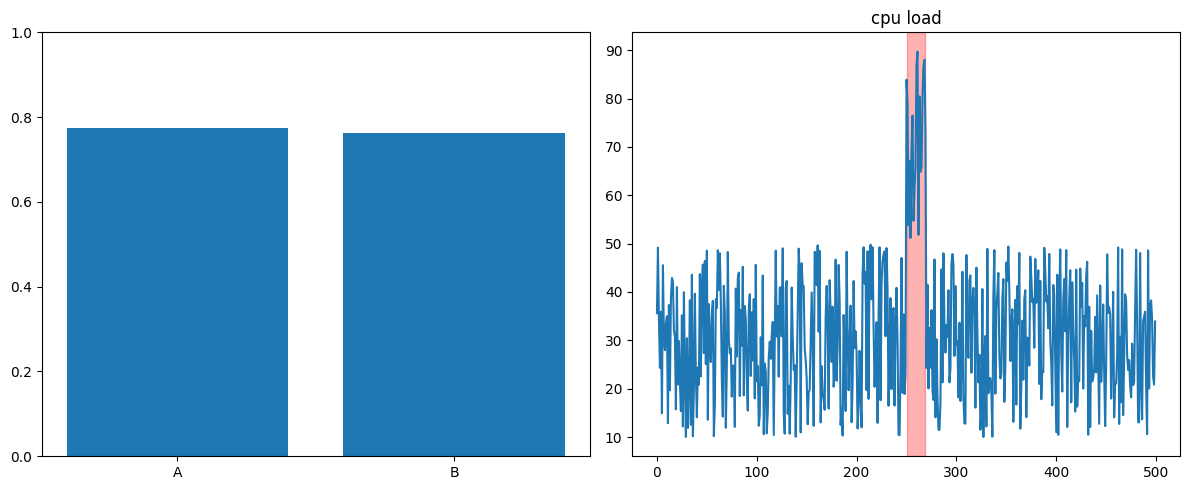

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

class TelemetryAuditor:
    def __init__(self):
        pass
        
    def evaluate_ab_test(self, test_df: pd.DataFrame) -> tuple:
        na = test_df[test_df['algo']=='A']['algo'].count()
        nb = test_df[test_df['algo']=='B']['algo'].count()
        xa = test_df[(test_df['success'] == 1) & (test_df['algo']=='A')]['success'].count()
        xb = test_df[(test_df['success'] == 1) & (test_df['algo']=='B')]['success'].count()
        # print(na, nb, xa, xb)

        pa = xa / na
        pb = xb / nb
        test = 'T' if any([
                            na * pa < 10,
                            na * (1 - pa) < 10,
                            nb * pb < 10,
                            nb * (1 - pb) < 10
                        ]) else 'Z'
        Ppool = (xa + xb) / (na + nb)
        se = np.sqrt(Ppool * (1 - Ppool) * ((1 / na) + (1 / nb)))
        Stat = (pa - pb) / se
        return test, float(round(Stat, 3))

    def find_max_load_window(self, load_array: np.ndarray, k: int) -> int:
        # print(load_array)
        cumsum = np.cumsum(load_array)
        # print(cumsum)
        window_sums = cumsum[k - 1:] - np.concatenate(([0], cumsum[:-k]))
        return int(np.argmax(window_sums))

    def visualize_ab_and_load(self, test_df: pd.DataFrame, load_array: np.ndarray, k: int):
        fig, ax = plt.subplots(1,2, figsize=(12,5))
        mean_rates = test_df.groupby('algo')['success'].mean()
        # print(mean_rates)
        ax[0].bar(['A', 'B'], [mean_rates['A'], mean_rates['B']])
        ax[0].set_ylim(0,1)
        strtat_idx = self.find_max_load_window(load_array.copy(), k)
        end_idx = strtat_idx + k - 1
        ax[1].plot(load_array)
        ax[1].set_title("cpu load")
        ax[1].axvspan(strtat_idx, end_idx, color = "red", alpha=0.3)
        plt.tight_layout()
        plt.show()

# --- Local Testing ---
if __name__ == "__main__":
    np.random.seed(42)
    
    # 1. Mock A/B Test Data (Large Sample - should trigger Z-test)
    n_large = 1000
    algo_large = np.random.choice(['A', 'B'], n_large)
    success_large = np.where(algo_large == 'A', 
                             np.random.choice([0, 1], n_large, p=[0.2, 0.8]), 
                             np.random.choice([0, 1], n_large, p=[0.25, 0.75]))
    df_large = pd.DataFrame({'algo': algo_large, 'success': success_large})
    
    # 2. Mock A/B Test Data (Small Sample - should trigger T-test condition)
    n_small = 30
    algo_small = np.random.choice(['A', 'B'], n_small)
    # Extremely low success rate for B to force successes < 10
    success_small = np.where(algo_small == 'A', 
                             np.random.choice([0, 1], n_small, p=[0.5, 0.5]), 
                             np.random.choice([0, 1], n_small, p=[0.9, 0.1]))
    df_small = pd.DataFrame({'algo': algo_small, 'success': success_small})
    
    # 3. Mock Load Array
    load_array = np.random.uniform(10.0, 50.0, 500)
    # Inject a known peak load window
    load_array[250:270] += 40.0 
    window_size = 20
    
    auditor = TelemetryAuditor()
    
    print("--- Statistical Evaluation ---")
    print(f"Large Sample Test: {auditor.evaluate_ab_test(df_large.copy())}")
    print(f"Small Sample Test: {auditor.evaluate_ab_test(df_small.copy())}")
    
    print("\n--- Sliding Window Audit ---")
    peak_idx = auditor.find_max_load_window(load_array.copy(), window_size)
    print(f"Peak load of size {window_size} starts at index: {peak_idx}")
    
    print("\n--- Visualization ---")
    # Uncomment to test your plotting function
    auditor.visualize_ab_and_load(df_large.copy(), load_array.copy(), window_size)